# 02 MongoDB: the document model and Mongo Q1-Q5

| | |
|---|---|
| **Question** | Which edits get reverted, how fast, and where (spec section 3), answered with MongoDB aggregation pipelines? |
| **Answer** | History cohort (reverts within 20 days): temporary accounts <!--fact:history_revert_rate_temporary_pct-->27.32<!--/fact-->% of edits reverted, registered users <!--fact:history_revert_rate_registered_pct-->4.03<!--/fact-->%; <!--fact:history_T_within_1h_pct-->49.86<!--/fact-->% of the reverts come within 1 hour. On the common 4-day horizon: <!--fact:history_T_within_1h_4d_pct-->55.66<!--/fact-->% (history) and <!--fact:live_T_within_1h_pct-->57.97<!--/fact-->% (live, PROVISIONAL) within 1 hour. Bots make <!--fact:mongo_q4_made_by_bot_pct-->5.03<!--/fact-->% of the revert actions. Top contested page: <!--fact:mongo_q2_top_page_title-->`Personality_and_image_of_Elizabeth_II`<!--/fact--> (score <!--fact:mongo_q2_top_page_score-->0.928571<!--/fact-->). |
| **Time to run** | about 30 seconds (Mongo Q5 alone takes about 15 seconds) |
| **Needs** | the local MongoDB loaded by `load_mongo.py` and `speed_layer.py` (Docker); Atlas is optional (`ATLAS_URI` in `ec-hw2/.env`). |

Human editors appear only as pseudonyms (`editor_` + 10 hex digits). Bots keep their names. All data times are UTC. Words: see `GLOSSARY.md`. Numbers: see `report/FACTS.md`. Every number in the text comes from there (`report/sync_notebook_text.py` copies it).

## Setup

**What:** Finds the project folder, imports `config.py` and the report helpers, and prints the data version.

**Why:** Every rule and path comes from `config.py`. The data version tells you which data release you have.

**You should see:** `DATA_VERSION: data-v1` (or a later version) and the path of the Python program.

In [1]:
# Set up the paths: this notebook is in ec-hw2/notebooks/, the project code is in ec-hw2/.
import sys, time, json
from pathlib import Path
HW2 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ec-hw2"
sys.path.insert(0, str(HW2))
import config
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, Markdown, display
from report import build_facts as facts      # FACTS.md helpers (check, tables with pseudonyms)
from report import make_figures as figs      # the report charts
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
T0 = time.time()

def _cell(v):
    if v is None or v is pd.NA or (isinstance(v, float) and v != v):
        return ""
    if isinstance(v, float):
        return f"{v:,.1f}" if abs(v) >= 1000 else f"{v:.4g}"
    return v

def show(df, n=None):
    """Print a table as text (it reads well on GitHub). Each cell keeps its own type."""
    d = df if n is None else df.head(n)
    rows = [[_cell(v) for v in r] for r in d.astype(object).itertuples(index=False)]
    print(tabulate(rows, headers=list(d.columns), tablefmt="github"))

print("DATA_VERSION:", config.DATA_VERSION)
print("Python:", sys.executable)

DATA_VERSION: data-v2
Python: /Users/scottnelson/Desktop/226/truth-lag/.venv/bin/python3


## 1. Connect

**What:** Connects to the local MongoDB and defines `run_query()`, which prints a pipeline from `queries/mongo/` and runs it once with `queries/run_mongo.py`.

**Why:** The notebook runs exactly the files that `run_mongo.py` wrote; it types no query itself.

**You should see:** `connected to the local MongoDB, version 8.0...` (the connection string is never printed).

In [2]:
import re
from comparison import compare            # json_array_text: the pipeline text as it is in the file
from queries import run_mongo
from load_mongo import connect
client = connect(config.MONGO_URI, 5000)
db = client[config.MONGO_DB]
print("connected to the local MongoDB, version", client.server_info()["version"], "- database", config.MONGO_DB)
QDIR = HW2 / "queries" / "mongo"
times = {}

def run_query(name, print_json=True):
    """Print the pipeline from queries/mongo/<name>.json, run it once, return the flat result tables."""
    path = QDIR / f"{name}.json"
    spec = run_mongo.load_query(path)
    if print_json:
        print(f"queries/mongo/{name}.json  (collection: {spec['collection']})")
        print(compare.json_array_text(path.read_text(), "pipeline"))
    t = time.perf_counter()
    out = run_mongo.run_pipeline(db, spec["collection"], spec["pipeline"], allow_disk=True)
    times[name] = round((time.perf_counter() - t) * 1000, 1)
    print(f"\n-> {len(out)} result documents in {times[name]:,.1f} ms (1 run in this notebook)\n")
    return run_mongo.flatten(name, out)

connected to the local MongoDB, version 8.0.34 - database truthlag


## 2. The schema and the indexes

**What:** Lists the collections with their document counts (per cohort for `revisions` and `revert_links`), and the indexes.

**Why:** This is the schema part of the Mongo section: what is stored, how much, and which indexes the queries use.

**You should see:** `revisions` with <!--fact:mongo_revisions_docs-->574,482<!--/fact--> documents (history + live), `revert_links` with <!--fact:mongo_revert_links_docs-->38,216<!--/fact-->, `page_hour` with <!--fact:mongo_page_hour_docs-->605,017<!--/fact-->, `tag_events` with <!--fact:mongo_tag_events_docs-->99,606<!--/fact-->, `late_reverts` with <!--fact:mongo_late_reverts_docs-->4,350<!--/fact-->, and the chart collections. Then <!--fact:mongo_indexes-->7<!--/fact--> indexes on `revisions` and `revert_links` (besides `_id_`): <!--fact:mongo_index_list-->revisions.page.id_1_ts_1; revisions.user.id_1; revisions.history.reverted_1; revisions.cohort_1_ts_1; revert_links.reverted_rev_id_1; revert_links.page_id_1; revert_links.cohort_1_page_id_1<!--/fact-->.

In [3]:
rows = []
for name in sorted(db.list_collection_names()):
    row = {"collection": name, "documents": db[name].estimated_document_count()}
    if name in (config.COL_REVISIONS, config.COL_REVERT_LINKS):
        for c in (config.COHORT_HISTORY, config.COHORT_LIVE):
            row[c] = db[name].count_documents({"cohort": c})
    rows.append(row)
coll = pd.DataFrame(rows)
for c in (config.COHORT_HISTORY, config.COHORT_LIVE):
    coll[c] = coll[c].astype("Int64")
show(coll)
print()
idx = []
for name in (config.COL_REVISIONS, config.COL_REVERT_LINKS):
    for iname, info in db[name].index_information().items():
        idx.append({"collection": name, "index": iname, "keys": info["key"]})
show(pd.DataFrame(idx))

| collection              |   documents |   history |   live |
|-------------------------|-------------|-----------|--------|
| chart_q1_hour_kind      |         147 |           |        |
| chart_q3_time_to_revert |          27 |           |        |
| chart_q5_known_by       |          72 |           |        |
| chart_q5_risk_deciles   |          11 |           |        |
| late_reverts            |        4350 |           |        |
| page_hour               |      605017 |           |        |
| page_hour_live          |        4658 |           |        |
| revert_links            |       38216 |     19858 |  18358 |
| revisions               |      574482 |    295016 | 279466 |
| tag_events              |       99606 |           |        |

| collection   | index              | keys                            |
|--------------|--------------------|---------------------------------|
| revisions    | _id_               | [('_id', 1)]                    |
| revisions    | page.id_1_

**What:** Lists the fields of one history document and one live document (field path and type only, no values).

**Why:** The document shape follows the spec: `page{}`, `user{}`, and a `history{}` or `live{}` part.

**You should see:** Paths such as `page.id (int)`, `user.kind (str)`, `history.secs_to_revert (int)` and `live.revert_risk (float)`.

In [4]:
def paths(doc, prefix=""):
    out = []
    for k, v in doc.items():
        p = f"{prefix}{k}"
        if isinstance(v, dict):
            out += paths(v, p + ".")
        else:
            out.append(f"{p} ({type(v).__name__})")
    return out
for c in (config.COHORT_HISTORY, config.COHORT_LIVE):
    d = db[config.COL_REVISIONS].find_one({"cohort": c, "user.kind": "bot"})   # a bot: no human name involved
    print(f"=== {c} document fields")
    print(", ".join(paths(d)))

=== history document fields
_id (str), wiki_db (str), rev_id (int), parent_id (int), cohort (str), page.id (int), page.title (str), page.ns (int), user.id (int), user.name (str), user.kind (str), user.key (str), user.is_bot (bool), user.is_anon (bool), user.is_temp (bool), user.edit_count (int), ts (datetime), hour_utc (int), size (int), size_delta (int), comment (str), tags (list), mw_reverted_tag (bool), is_revert (bool), revert_method (NoneType), history.snapshot (str), history.reverted (bool), history.reverted_any (bool), history.secs_to_revert (NoneType), history.reverting_rev_id (NoneType), history.reverter (NoneType), history.reverted_by_other (bool), history.followup_s (int), history.page_edits_prev_1h (int)
=== live document fields
_id (str), wiki_db (str), rev_id (int), parent_id (int), cohort (str), page.id (int), page.title (str), page.ns (int), user.id (int), user.name (str), user.kind (str), user.key (str), user.is_bot (bool), user.is_anon (bool), user.is_temp (bool), use

## 3. Mongo Q1: revert rate by hour of day and user kind

**What:** Mongo Q1: prints the pipeline and runs it. The revert rate by hour of day (UTC) and user kind, for both cohorts. The live half uses `$unionWith` and a `$lookup` to `revert_links`.

**Why:** Spec 3.1. It shows who gets reverted and when.

**You should see:** 147 rows (cohort x hour x user kind). Reverted means within 20 days (history) or within 4 days (live). History cohort: temporary accounts between <!--fact:mongo_q1_history_temporary_hourly_min_pct-->22.24<!--/fact-->% and <!--fact:mongo_q1_history_temporary_hourly_max_pct-->30.41<!--/fact-->% in every hour, registered users between <!--fact:mongo_q1_history_registered_hourly_min_pct-->3.23<!--/fact-->% and <!--fact:mongo_q1_history_registered_hourly_max_pct-->5.71<!--/fact-->%, bots under 3%. Then 2 sentences of facts and the chart.

queries/mongo/q1_revert_rate_by_hour.json  (collection: revisions)
  "pipeline": [
    {"$match": {"cohort": "history"}},
    {
      "$project": {
        "_id": 0,
        "cohort": 1,
        "hour_utc": 1,
        "user_kind": "$user.kind",
        "reverted": "$history.reverted"
      }
    },
    {
      "$unionWith": {
        "coll": "revisions",
        "pipeline": [
          {"$match": {"cohort": "live"}},
          {
            "$lookup": {
              "from": "revert_links",
              "localField": "rev_id",
              "foreignField": "reverted_rev_id",
              "let": {"c": "$cohort"},
              "pipeline": [
                {"$match": {"$expr": {"$eq": ["$cohort", "$$c"]}, "within_followup": true}},
                {"$project": {"_id": 0, "T_s": 1}}
              ],
              "as": "link"
            }
          },
          {
            "$project": {
              "_id": 0,
              "cohort": 1,
              "hour_utc": 1,
              "us


-> 147 result documents in 5,433.4 ms (1 run in this notebook)

| cohort   |   hour_utc | user_kind   |   edits |   reverted |   revert_rate |
|----------|------------|-------------|---------|------------|---------------|
| history  |          0 | bot         |    2432 |          8 |      0.003289 |
| history  |          0 | registered  |    9669 |        314 |      0.03247  |
| history  |          0 | temporary   |    1298 |        326 |      0.2512   |
| history  |          1 | bot         |    1559 |         11 |      0.007056 |
| history  |          1 | registered  |    8726 |        282 |      0.03232  |
| history  |          1 | temporary   |    1437 |        417 |      0.2902   |
| history  |          2 | bot         |    3900 |          4 |      0.001026 |
| history  |          2 | registered  |    8698 |        305 |      0.03507  |
| history  |          2 | temporary   |    1545 |        443 |      0.2867   |

Facts: in the history cohort, 27.3% of edits by temporary account

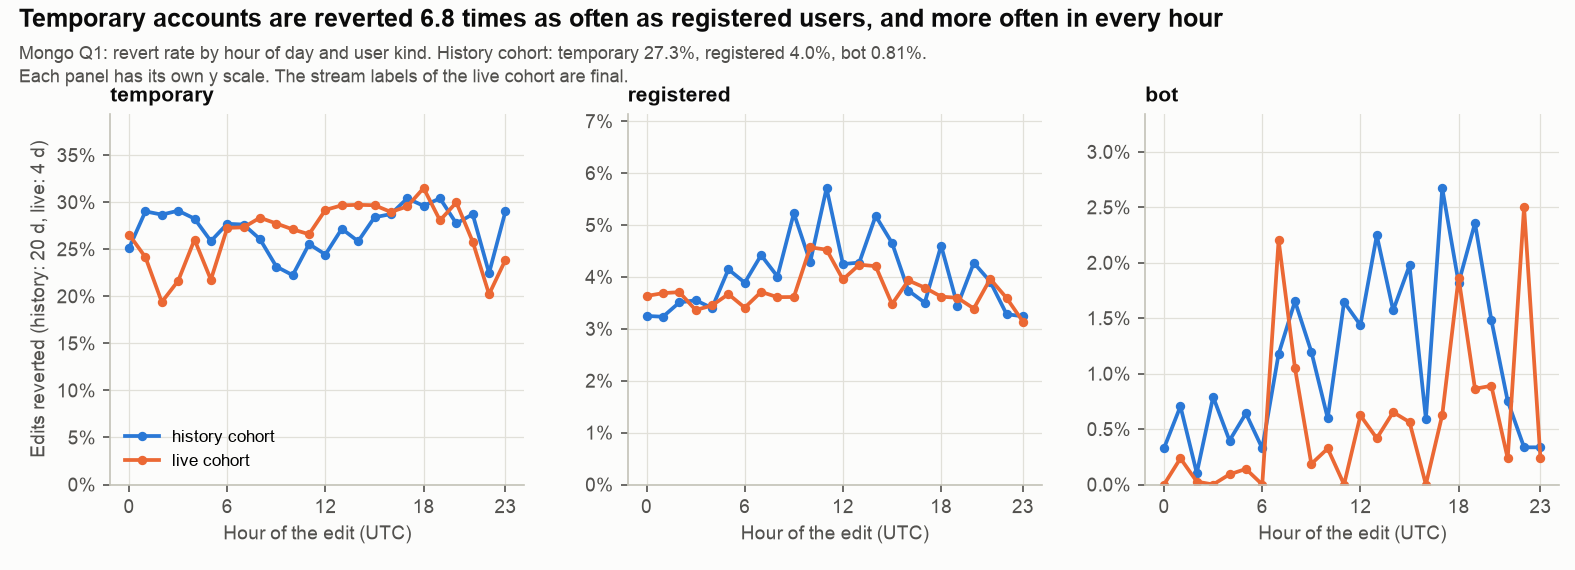

In [5]:
q1 = run_query("q1_revert_rate_by_hour")[""]
show(q1, 9)
h = q1[q1["cohort"] == "history"].groupby("user_kind")[["edits", "reverted"]].sum()
h["rate"] = h["reverted"] / h["edits"]
tmp = q1[(q1["cohort"] == "history") & (q1["user_kind"] == "temporary")]
peak = tmp.sort_values("revert_rate", ascending=False).iloc[0]
print(f"\nFacts: in the history cohort, {100 * h.loc['temporary', 'rate']:.1f}% of edits by temporary accounts were "
      f"reverted, against {100 * h.loc['registered', 'rate']:.1f}% for registered users and {100 * h.loc['bot', 'rate']:.2f}% for bots. "
      f"The highest hourly rate for temporary accounts is {100 * peak['revert_rate']:.1f}% at {int(peak['hour_utc'])}:00 UTC.")
display(Image(filename=str(figs.revert_rate_by_hour_figure(q1))))

## 4. Mongo Q2: top 20 contested pages

**What:** Mongo Q2: the top 20 contested pages of the history cohort (score = revert actions by other editors / human edits; at least 10 human edits and 2 reverted editors).

**Why:** Spec 3.2, and the 'top contested pages' question of the comparison (notebook 04).

**You should see:** 20 pages; rank 1 is <!--fact:mongo_q2_top_page_title-->`Personality_and_image_of_Elizabeth_II`<!--/fact--> with <!--fact:mongo_q2_top_page_revert_actions-->13<!--/fact--> revert actions on <!--fact:mongo_q2_top_page_edits-->14<!--/fact--> human edits.

In [6]:
q2 = run_query("q2_top_contested_pages")[""]
show(q2, 20)
top = q2.iloc[0]
print(f"\nFacts: the most contested page is {top['page_title']}: {int(top['revert_actions'])} revert actions on "
      f"{int(top['edits'])} human edits (score {top['score']:.6f}). All {int(q2['contested'].sum())} of the top 20 pages "
      f"pass the 'contested' rule.")

queries/mongo/q2_top_contested_pages.json  (collection: revert_links)
  "pipeline": [
    {"$match": {"cohort": "history", "within_followup": true, "by_other": true}},
    {
      "$group": {
        "_id": "$page_id",
        "actions": {"$addToSet": "$reverting_rev_id"},
        "editors": {"$addToSet": "$author_key"}
      }
    },
    {
      "$project": {
        "revert_actions": {"$size": "$actions"},
        "reverted_editors": {"$size": "$editors"}
      }
    },
    {"$match": {"reverted_editors": {"$gte": 2}}},
    {
      "$lookup": {
        "from": "revisions",
        "localField": "_id",
        "foreignField": "page.id",
        "pipeline": [
          {"$match": {"cohort": "history"}},
          {"$sort": {"ts": 1}},
          {
            "$group": {
              "_id": null,
              "edits": {"$sum": {"$cond": ["$user.is_bot", 0, 1]}},
              "title": {"$last": "$page.title"}
            }
          }
        ],
        "as": "rev"
      }
    },
    


-> 20 result documents in 127.9 ms (1 run in this notebook)

|   rank |   page_id | page_title                               |   edits |   revert_actions |   reverted_editors |   score | contested   |
|--------|-----------|------------------------------------------|---------|------------------|--------------------|---------|-------------|
|      1 |  11383948 | Personality_and_image_of_Elizabeth_II    |      14 |               13 |                  5 |  0.9286 | True        |
|      2 |     52382 | Watergate_scandal                        |      32 |               28 |                 14 |  0.875  | True        |
|      3 |   3146234 | PB&J_Otter                               |      39 |               34 |                 13 |  0.8718 | True        |
|      4 |  82920850 | Jim_Queen                                |      14 |               12 |                  8 |  0.8571 | True        |
|      5 |   3040638 | Pororo_the_Little_Penguin                |      13 |               11 |    

## 5. Mongo Q3: time to revert

**What:** Mongo Q3: the distribution of the time to revert T with `$bucket` on the lag grid of `config.py`. It has 3 series:
- `history`: the history reverts within 20 days;
- `history_4d`: the history reverts within 4 days, with the shares computed again on that smaller total;
- `live`: the live reverts within 4 days (PROVISIONAL: the live follow-up is still short).

**Why:** Spec 3.3. It answers 'how fast'. The two cohorts have different horizons. So compare `live` only with `history_4d` (both 4 days), never with `history`.

**You should see:** <!--fact:mongo_q3_history_buckets-->11<!--/fact--> `history` buckets, <!--fact:mongo_q3_history_4d_buckets-->8<!--/fact--> `history_4d` buckets and <!--fact:mongo_q3_live_buckets-->8<!--/fact--> `live` buckets. The default bucket `over_20d` is empty.
- Within 1 minute: <!--fact:mongo_q3_history_lt_1min_pct-->17.61<!--/fact-->% of the history reverts (20 days). On the 4-day horizon: <!--fact:mongo_q3_history_4d_lt_1min_pct-->19.66<!--/fact-->% (history) and <!--fact:mongo_q3_live_lt_1min_pct-->23.28<!--/fact-->% (live).
- Within 1 hour: <!--fact:history_T_within_1h_pct-->49.86<!--/fact-->% of the history reverts (20 days). On the 4-day horizon: <!--fact:history_T_within_1h_4d_pct-->55.66<!--/fact-->% (history) and <!--fact:live_T_within_1h_pct-->57.97<!--/fact-->% (live).

Then the chart: the 20-day history series on the left, the 4-day comparison on the right.

queries/mongo/q3_time_to_revert.json  (collection: revert_links)
  "pipeline": [
    {"$match": {"cohort": {"$in": ["history", "live"]}, "within_followup": true}},
    {
      "$facet": {
        "history": [
          {"$match": {"cohort": "history"}},
          {
            "$bucket": {
              "groupBy": "$T_s",
              "boundaries": [
                0,
                60,
                300,
                900,
                3600,
                21600,
                86400,
                172800,
                345600,
                604800,
                1209600,
                1728001
              ],
              "default": "over_20d",
              "output": {"n": {"$sum": 1}}
            }
          }
        ],
        "live": [
          {"$match": {"cohort": "live"}},
          {
            "$bucket": {
              "groupBy": "$T_s",
              "boundaries": [
                0,
                60,
                300,
                900,
 

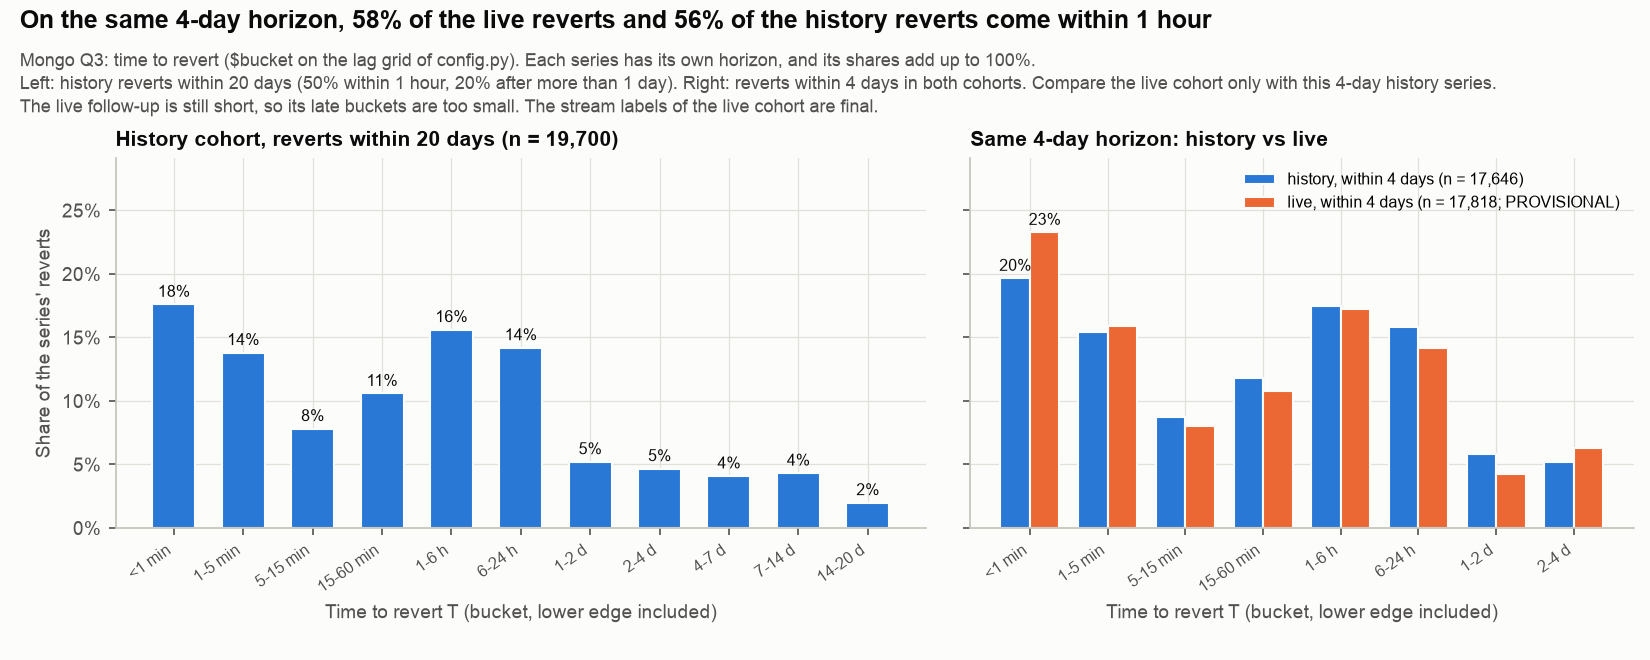

In [7]:
q3 = run_query("q3_time_to_revert")[""]
show(q3)
hq = q3[q3["cohort"] == "history"].set_index("bucket")
h4 = q3[q3["cohort"] == "history_4d"].set_index("bucket")
lq = q3[q3["cohort"] == "live"].set_index("bucket")
print(f"\nFacts: {100 * hq.loc['<1 min', 'share']:.1f}% of the history reverts within 20 days come within 1 minute and "
      f"{100 * hq.loc['15-60 min', 'cum_share']:.1f}% within 1 hour; {100 * (1 - hq.loc['6-24 h', 'cum_share']):.1f}% take "
      f"more than 1 day. On the same 4-day horizon, {100 * h4.loc['15-60 min', 'cum_share']:.1f}% of the history reverts "
      f"and {100 * lq.loc['15-60 min', 'cum_share']:.1f}% of the live reverts (PROVISIONAL) come within 1 hour.")
display(Image(filename=str(figs.time_to_revert_figure(q3))))

## 6. Mongo Q4: bot vs human

**What:** Mongo Q4: bot vs human share of reverts, with one `$facet` (reverts by another editor within 20 days).

**Why:** Spec 3.4. It answers 'who reverts' and 'who gets reverted'.

**You should see:** Revert actions made: registered <!--fact:mongo_q4_made_by_registered_pct-->88.88<!--/fact-->%, temporary <!--fact:mongo_q4_made_by_temporary_pct-->6.09<!--/fact-->%, bot <!--fact:mongo_q4_made_by_bot_pct-->5.03<!--/fact-->%. Reverted revisions received: temporary <!--fact:mongo_q4_received_by_temporary_pct-->55.66<!--/fact-->%. Then the chart.

queries/mongo/q4_bot_vs_human.json  (collection: revert_links)
  "pipeline": [
    {"$match": {"cohort": "history", "within_followup": true, "by_other": true}},
    {
      "$facet": {
        "made_by_reverter_kind": [
          {
            "$group": {
              "_id": {"kind": "$reverter_kind", "rev": "$reverting_rev_id"},
              "links": {"$sum": 1}
            }
          },
          {
            "$group": {
              "_id": "$_id.kind",
              "revert_actions": {"$sum": 1},
              "reverted_revisions": {"$sum": "$links"}
            }
          },
          {"$project": {"_id": 0, "kind": "$_id", "revert_actions": 1, "reverted_revisions": 1}},
          {"$setWindowFields": {"output": {"total": {"$sum": "$revert_actions"}}}},
          {"$addFields": {"share": {"$divide": ["$revert_actions", "$total"]}}},
          {"$project": {"total": 0}},
          {"$sort": {"revert_actions": -1, "kind": 1}}
        ],
        "received_by_author_kind": [
    


-> 1 result documents in 298.0 ms (1 run in this notebook)

| part                    | kind       |   revert_actions |   reverted_revisions |    share |   edits |   reverted |   reverted_by_other |   revert_rate |   revert_rate_by_other |
|-------------------------|------------|------------------|----------------------|----------|---------|------------|---------------------|---------------|------------------------|
| made_by_reverter_kind   | registered |            11886 |                16105 | 0.8888   |         |            |                     |               |                        |
| made_by_reverter_kind   | temporary  |              815 |                 1024 | 0.06094  |         |            |                     |               |                        |
| made_by_reverter_kind   | bot        |              672 |                  739 | 0.05025  |         |            |                     |               |                        |
| received_by_author_kind | temporary  

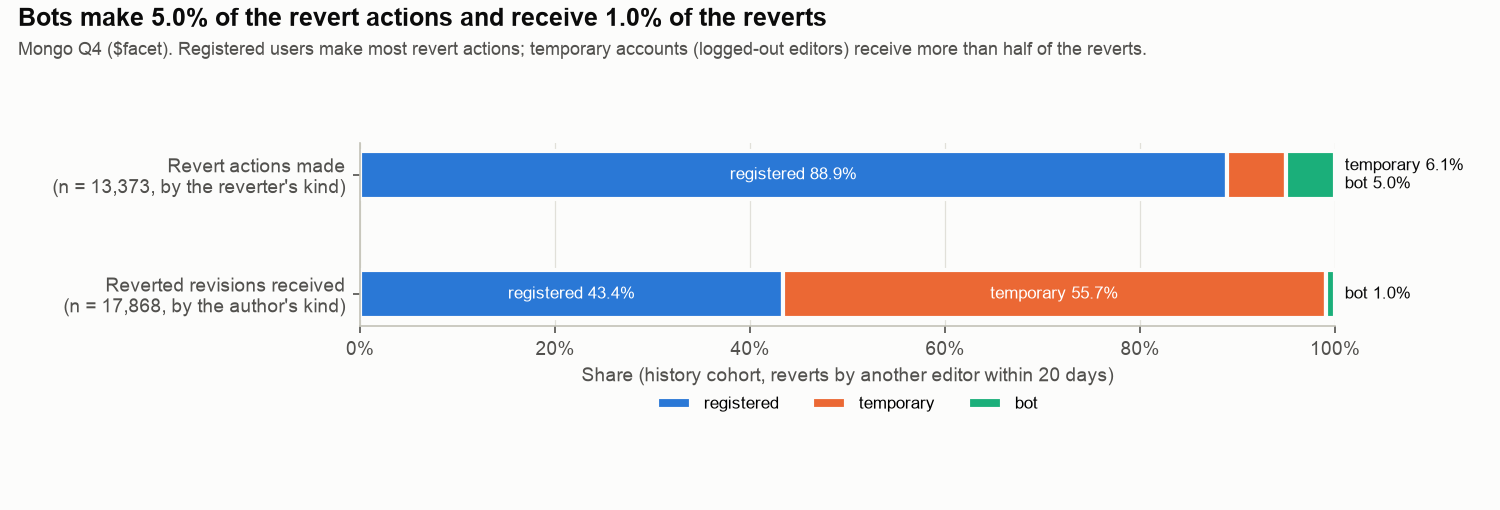

In [8]:
q4 = run_query("q4_bot_vs_human")[""]
show(q4)
made = q4[q4["part"] == "made_by_reverter_kind"].set_index("kind")
recv = q4[q4["part"] == "received_by_author_kind"].set_index("kind")
rate = q4[q4["part"] == "edit_revert_rate"].set_index("kind")
print(f"\nFacts: bots made {100 * made.loc['bot', 'share']:.1f}% of the {int(made['revert_actions'].sum()):,} revert actions "
      f"and received {100 * recv.loc['bot', 'share']:.1f}% of the {int(recv['reverted_revisions'].sum()):,} reverted revisions. "
      f"A bot edit is reverted in {100 * rate.loc['bot', 'revert_rate']:.2f}% of cases, a human edit in {100 * rate.loc['human', 'revert_rate']:.2f}%.")
display(Image(filename=str(figs.bot_vs_human_figure(q4))))

## 7. Mongo Q5: truth-lag preview

**What:** Mongo Q5: the truth-lag preview. For each cohort and user kind, the share of eventual reverts (within 4 days) already visible after each wait; the live cohort adds the stream delay K. The second table is the revert rate by the page's activity in the hour before the edit (`page_hour` from the speed layer, and the sliding hour).

**Why:** Spec 3.5: live signals ($lookup) against the eventual revert label. Notebook 05 goes deeper.

**You should see:** 72 known-by rows and 15 activity rows. After 1 h, <!--fact:mongo_q5_history_known_1h_pct-->55.66<!--/fact-->% of the history reverts (within 4 days) are visible, and <!--fact:mongo_q5_live_known_1h_pct-->57.95<!--/fact-->% of the live ones (PROVISIONAL).

In [9]:
q5 = run_query("q5_truth_lag_preview")
known, act = q5[""], q5["_activity"]
show(known[known["user_kind"] == "all"])
print()
show(act)
kh = known[(known["cohort"] == "history") & (known["user_kind"] == "all")].set_index("wait")
kl = known[(known["cohort"] == "live") & (known["user_kind"] == "all")].set_index("wait")
print(f"\nFacts: after 1 hour, {100 * kh.loc['1 h', 'share_known']:.1f}% of the history reverts (within 4 days) are visible, "
      f"and {100 * kl.loc['1 h', 'share_known']:.1f}% of the live ones (PROVISIONAL). After 1 day: "
      f"{100 * kh.loc['1 d', 'share_known']:.1f}% and {100 * kl.loc['1 d', 'share_known']:.1f}%.")

queries/mongo/q5_truth_lag_preview.json  (collection: revisions)
  "pipeline": [
    {"$match": {"cohort": {"$in": ["history", "live"]}}},
    {
      "$lookup": {
        "from": "revert_links",
        "localField": "rev_id",
        "foreignField": "reverted_rev_id",
        "let": {"c": "$cohort"},
        "pipeline": [
          {"$match": {"$expr": {"$eq": ["$cohort", "$$c"]}}},
          {"$project": {"_id": 0, "T_s": 1, "K_s": 1}}
        ],
        "as": "link"
      }
    },
    {
      "$addFields": {
        "prev_hour_key": {
          "$cond": [
            {"$eq": ["$cohort", "live"]},
            {
              "$concat": [
                {"$toString": "$page.id"},
                ":",
                {
                  "$dateToString": {
                    "date": {
                      "$dateSubtract": {"startDate": "$live.seen_ts", "unit": "hour", "amount": 1}
                    },
                    "format": "%Y-%m-%dT%H",
                    "timezone": "UT


-> 1 result documents in 16,365.3 ms (1 run in this notebook)

| cohort   | user_kind   | wait   |   wait_s |   n_edits |   n_reverted_4d |   revert_rate_4d |   known |   share_known | wait_sorted   |
|----------|-------------|--------|----------|-----------|-----------------|------------------|---------|---------------|---------------|
| history  | all         | 0      |        0 |    295016 |           17646 |          0.05981 |       0 |        0      | 01 0          |
| history  | all         | 1 min  |       60 |    295016 |           17646 |          0.05981 |    3506 |        0.1987 | 02 1 min      |
| history  | all         | 5 min  |      300 |    295016 |           17646 |          0.05981 |    6204 |        0.3516 | 03 5 min      |
| history  | all         | 15 min |      900 |    295016 |           17646 |          0.05981 |    7737 |        0.4385 | 04 15 min     |
| history  | all         | 1 h    |     3600 |    295016 |           17646 |          0.05981 |    9822 |   

## 8. Timings

**What:** Shows the timings: the median of 7 warm runs from `results/mongo_summary.csv` (made by `queries/run_mongo.py`), next to the single run in this notebook.

**Why:** The Mongo section reports query times. Use the 7-run medians in the report; one run is only a check.

**You should see:** Q1 about 5 s, Q5 about 15 s (both read the <!--fact:mongo_revisions_docs-->574,482<!--/fact--> `revisions` documents with a `$lookup`), Q2-Q4 under 0.3 s. Mongo Q2 and `compare_mutual_reverts` are also comparison queries. Their times here are single-engine runs: for the comparison, use `cmp_ms_*` from `results/comparison.csv` (notebook 04).

In [10]:
ms = pd.read_csv(config.RESULTS_DIR / "mongo_summary.csv")
ms["this notebook, 1 run (ms)"] = ms["query"].map(times)
show(ms)

| query                  | collection   |   result_rows |   median_ms |   min_ms |   max_ms |   runs |   this notebook, 1 run (ms) |
|------------------------|--------------|---------------|-------------|----------|----------|--------|-----------------------------|
| q1_revert_rate_by_hour | revisions    |           147 |      5362.2 |   5322.3 |   5526.1 |      7 |                      5433.4 |
| q2_top_contested_pages | revert_links |            20 |        76.9 |     75.5 |     78.3 |      7 |                       127.9 |
| q3_time_to_revert      | revert_links |            27 |        50.5 |     49.9 |     54.2 |      7 |                        65.1 |
| q4_bot_vs_human        | revert_links |             8 |       270.8 |    267.1 |    358.5 |      7 |                       298   |
| q5_truth_lag_preview   | revisions    |            72 |     15541.7 |  15277.7 |  16598.5 |      7 |                     16365.3 |
| compare_mutual_reverts | revert_links |           462 |       128.5

## 9. Atlas status

**What:** Checks Atlas. If `ATLAS_URI` is set in `ec-hw2/.env`, it counts the documents on Atlas. If not, it says 'Atlas not loaded yet'. In both cases it prints the size estimate of the Atlas copy (`load_mongo.py`).

**Why:** Spec 3 asks for the Atlas free tier (M0, 512 MB). We stay under a 400 MB budget.

**You should see:** The Atlas collections with their counts: `revisions` <!--fact:history_revisions-->295,016<!--/fact--> and `revert_links` <!--fact:history_revert_links-->19,858<!--/fact--> (history cohort only), and the 4 chart collections. Or `Atlas not loaded yet`. Then the estimate of about <!--fact:atlas_estimate_mb-->229.7<!--/fact--> MB (fits). The connection string is never printed.

In [11]:
import load_mongo
if config.ATLAS_URI:
    try:
        adb = connect(config.ATLAS_URI, 15000)[config.ATLAS_DB]
        show(pd.DataFrame([{"Atlas collection": n, "documents": adb[n].estimated_document_count()}
                           for n in sorted(adb.list_collection_names())]))
    except Exception as exc:
        print(f"Atlas is set in .env but not reachable: {type(exc).__name__}")
else:
    print("Atlas not loaded yet (ATLAS_URI is empty in ec-hw2/.env). Size estimate of the Atlas copy:")
est = load_mongo.estimate_atlas_size(load_mongo.local_chart_documents())
load_mongo.print_estimate(est)

| Atlas collection        |   documents |
|-------------------------|-------------|
| chart_q1_hour_kind      |         147 |
| chart_q3_time_to_revert |          27 |
| chart_q5_known_by       |          72 |
| chart_q5_risk_deciles   |          11 |
| revert_links            |       19858 |
| revisions               |      295016 |


collection                  documents  avg bytes   data MB  index MB
revisions                     295,016      592.2    166.62     52.05
revert_links                   19,858      434.6      8.23      2.76
chart_q1_hour_kind                147      153.7      0.02      0.01
chart_q3_time_to_revert            27      214.6      0.01      0.00
chart_q5_known_by                  72      232.5      0.02      0.00
chart_q5_risk_deciles              11      450.6      0.00      0.00
estimated total 229.7 MB; budget 400 MB (the free tier limit is 512 MB) -> fits


## Check against FACTS.md

**What:** Compares the key numbers of this notebook with `report/FACTS.md`. Then it checks every number in the text of this notebook (the fact markers) against FACTS.md.

**Why:** The report uses FACTS.md. If a number here is different, the data or the code changed: tell the Report+GenAI owner before you copy any number.

**You should see:** Two tables with one row per number, and the lines `OK: all ... numbers match FACTS.md` and `OK: all ... numbers in the text match FACTS.md`. `DIFFERENT` means a number changed (normal for PROVISIONAL numbers after the live refresh). Then run `report/build_facts.py` and `report/sync_notebook_text.py` again.

In [12]:
facts.check({
    "mongo_revisions_docs": int(coll.set_index("collection").loc[config.COL_REVISIONS, "documents"]),
    "mongo_revert_links_docs": int(coll.set_index("collection").loc[config.COL_REVERT_LINKS, "documents"]),
    "mongo_page_hour_docs": int(coll.set_index("collection").loc[config.COL_PAGE_HOUR, "documents"]),
    "mongo_indexes": len([i for i in idx if i["index"] != "_id_"]),
    "history_revert_rate_temporary_pct": 100 * h.loc["temporary", "rate"],
    "history_revert_rate_registered_pct": 100 * h.loc["registered", "rate"],
    "mongo_q2_top_page_title": top["page_title"],
    "mongo_q2_top_page_score": top["score"],
    "mongo_q2_contested_in_top20": int(q2["contested"].sum()),
    "mongo_q3_history_lt_1min_pct": 100 * hq.loc["<1 min", "share"],
    "mongo_q3_history_4d_lt_1min_pct": 100 * h4.loc["<1 min", "share"],
    "mongo_q3_live_lt_1min_pct": 100 * lq.loc["<1 min", "share"],
    "mongo_q3_history_4d_buckets": len(h4),
    "history_T_within_1h_4d_pct": 100 * h4.loc["15-60 min", "cum_share"],
    "live_T_within_1h_pct": 100 * lq.loc["15-60 min", "cum_share"],
    "history_T_within_1h_pct": 100 * hq.loc["15-60 min", "cum_share"],
    "mongo_q4_made_by_bot_pct": 100 * made.loc["bot", "share"],
    "mongo_q4_received_by_bot_pct": 100 * recv.loc["bot", "share"],
    "mongo_q4_received_by_temporary_pct": 100 * recv.loc["temporary", "share"],
    "mongo_q5_history_known_1h_pct": 100 * kh.loc["1 h", "share_known"],
    "mongo_q5_live_known_1h_pct": 100 * kl.loc["1 h", "share_known"],
    "atlas_estimate_mb": est["total_mb"],
})
print()
from report import sync_notebook_text
sync_notebook_text.check_markers(HW2 / "notebooks" / "02_mongodb.ipynb")
print(f"\nnotebook time: {time.time() - T0:.0f} s")

| key                                | FACTS.md                              | notebook                              | status   | result   |
|------------------------------------|---------------------------------------|---------------------------------------|----------|----------|
| mongo_revisions_docs               | 574,482                               | 574,482                               | FINAL    | OK       |
| mongo_revert_links_docs            | 38,216                                | 38,216                                | FINAL    | OK       |
| mongo_page_hour_docs               | 605,017                               | 605,017                               | FINAL    | OK       |
| mongo_indexes                      | 7                                     | 7                                     | FINAL    | OK       |
| history_revert_rate_temporary_pct  | 27.32                                 | 27.32                                 | FINAL    | OK       |
| history_rev

Numbers in the text of 02_mongodb.ipynb (fact markers):
| cell   | key                                        | text                                                                                                                                                                                          | FACTS.md                                                                                                                                                                                      | result   |
|--------|--------------------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|----------|
| 0      | history_revert_rate_temporary_p